# Analysing interaction logs: does AI support change decisions?

This notebook analyses the CSV logs written by `src/viewer.py`.

**Data note:** by default it loads `logs/simulated_sessions.csv`, which is **simulated**
(see `scripts/simulate_sessions.py`). The numbers below only demonstrate the analysis
pipeline - they are not study results. To analyse real sessions, set `USE_REAL_LOGS = True`.

Questions:
1. Are decisions more accurate with or without the AI suggestion?
2. Are decisions faster with the AI suggestion?
3. **Automation bias:** when the AI is wrong, how often do users follow it?

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
USE_REAL_LOGS = False

if USE_REAL_LOGS:
    files = sorted((ROOT / "logs").glob("session_*.csv"))
    logs = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
else:
    logs = pd.read_csv(ROOT / "logs" / "simulated_sessions.csv")

print(f"{len(logs)} events, {logs.participant_id.nunique()} participants")
logs.event.value_counts()

1728 events, 12 participants


event
rating           1536
case_open          96
case_complete      96
Name: count, dtype: int64

## 1. One row per decision

We keep only `rating` events and compute the time each decision took
(difference to the previous event in the same case).

In [2]:
logs = logs.sort_values(["session_id", "case_id", "ms_since_case_open"])
logs["decision_ms"] = logs.groupby(["session_id", "case_id"])["ms_since_case_open"].diff()

decisions = logs[logs.event == "rating"].copy()
decisions["correct"] = (decisions.rating == decisions.ground_truth).astype(int)
decisions[["participant_id", "case_id", "ai_condition", "region", "z_score",
           "ai_flag", "rating", "ground_truth", "correct", "decision_ms"]].head()

,participant_id,case_id,ai_condition,region,z_score,ai_flag,rating,ground_truth,correct,decision_ms
1,SIM01,CASE-01,ai_on,Left Hippocampus,0.27,0.0,0.0,0.0,1,1792.0
2,SIM01,CASE-01,ai_on,Right Hippocampus,0.68,0.0,0.0,0.0,1,1345.0
3,SIM01,CASE-01,ai_on,Left Entorhinal cortex,-1.76,1.0,1.0,0.0,0,1643.0
4,SIM01,CASE-01,ai_on,Right Entorhinal cortex,0.12,0.0,0.0,0.0,1,2307.0
5,SIM01,CASE-01,ai_on,Left Amygdala,-0.02,0.0,0.0,0.0,1,1977.0


## 2. Accuracy and decision time by condition

In [3]:
per_person = (decisions
              .groupby(["participant_id", "ai_condition"])
              .agg(accuracy=("correct", "mean"), median_time_s=("decision_ms", lambda s: s.median() / 1000))
              .reset_index())
summary = per_person.groupby("ai_condition")[["accuracy", "median_time_s"]].agg(["mean", "std"]).round(3)
summary

accuracy        median_time_s       
                 mean    std          mean    std
ai_condition                                     
ai_off          0.840  0.061         2.441  0.104
ai_on           0.819  0.026         2.007  0.061

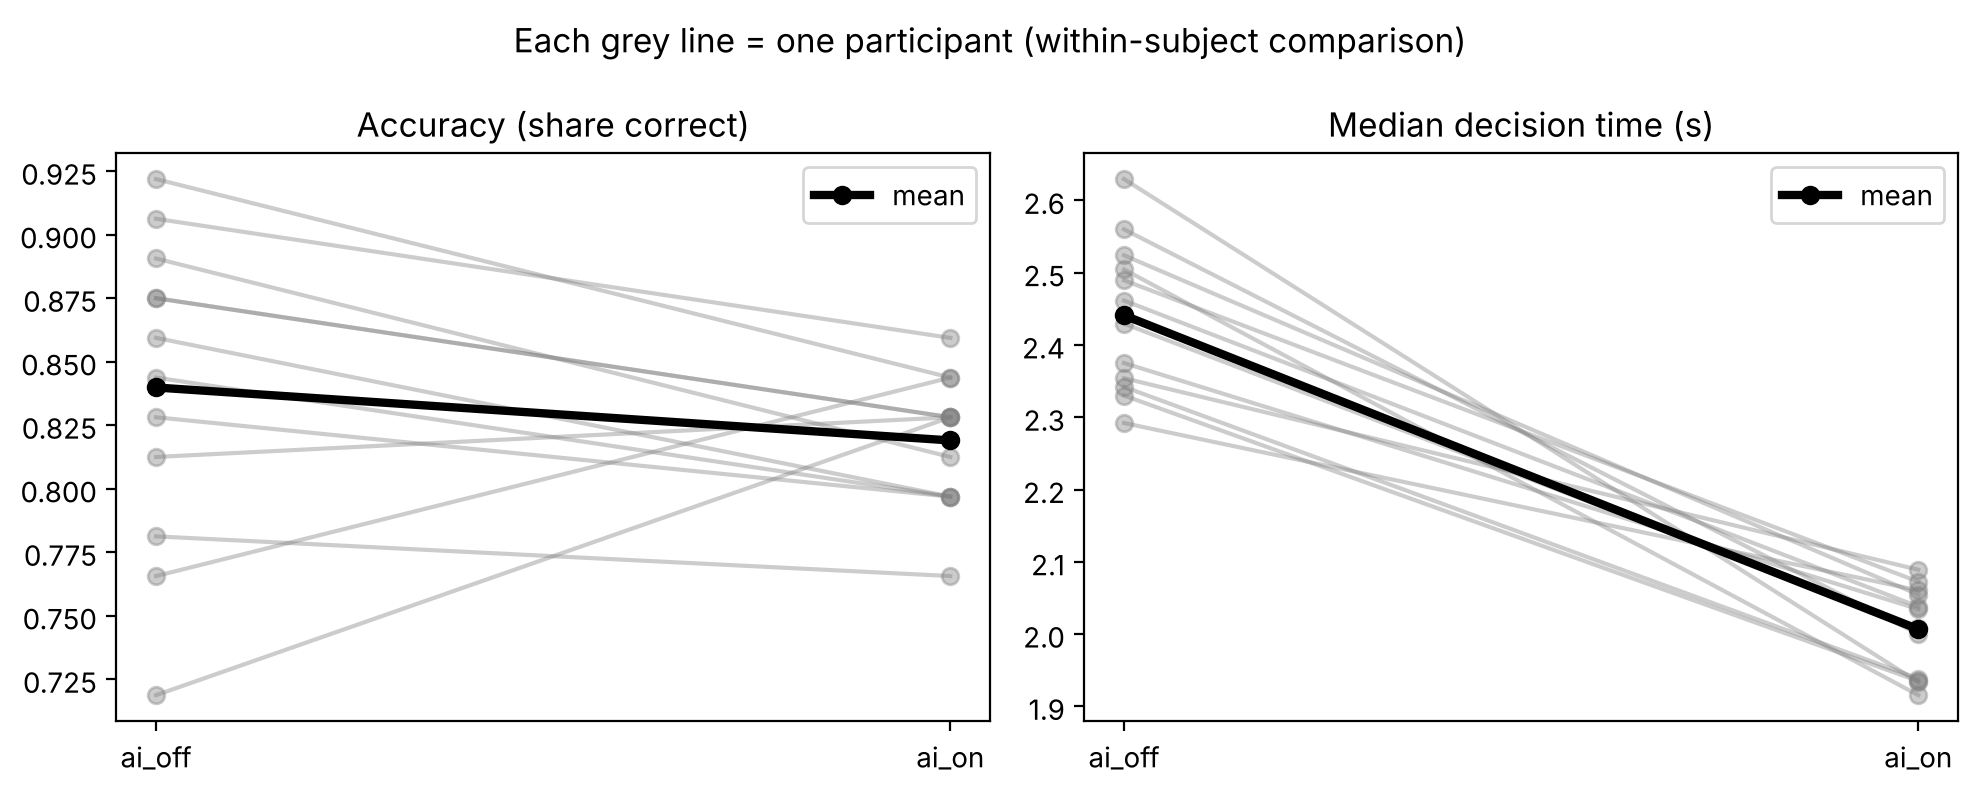

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
order = ["ai_off", "ai_on"]
for ax, col, label in [(axes[0], "accuracy", "Accuracy (share correct)"),
                       (axes[1], "median_time_s", "Median decision time (s)")]:
    wide = per_person.pivot(index="participant_id", columns="ai_condition", values=col)[order]
    for _, row in wide.iterrows():
        ax.plot(order, row.values, color="grey", alpha=0.4, marker="o")
    ax.plot(order, wide.mean().values, color="black", linewidth=3, marker="o", label="mean")
    ax.set_title(label)
    ax.legend()
plt.suptitle("Each grey line = one participant (within-subject comparison)")
plt.tight_layout()
plt.savefig(ROOT / "figures" / "accuracy_time_by_condition.png", dpi=150)
plt.show()

A paired test is appropriate because every participant saw both conditions.
With small samples we use the non-parametric Wilcoxon signed-rank test.

In [5]:
from scipy.stats import wilcoxon

for col in ["accuracy", "median_time_s"]:
    wide = per_person.pivot(index="participant_id", columns="ai_condition", values=col)
    stat, p = wilcoxon(wide["ai_on"], wide["ai_off"])
    print(f"{col}: mean ai_off={wide['ai_off'].mean():.3f}, ai_on={wide['ai_on'].mean():.3f}, Wilcoxon p={p:.3f}")

accuracy: mean ai_off=0.840, ai_on=0.819, Wilcoxon p=0.238
median_time_s: mean ai_off=2.441, ai_on=2.007, Wilcoxon p=0.000


## 3. Automation bias

For decisions where the AI was shown, split by whether the AI was right or wrong.
If users follow a **wrong** AI suggestion, that is a sign of over-reliance.

In [6]:
ai_on = decisions[decisions.ai_condition == "ai_on"].copy()
ai_on["ai_correct"] = (ai_on.ai_flag == ai_on.ground_truth)
ai_on["followed_ai"] = (ai_on.rating == ai_on.ai_flag)

bias = (ai_on.groupby("ai_correct")
        .agg(n=("followed_ai", "size"), followed_ai=("followed_ai", "mean"), accuracy=("correct", "mean"))
        .round(3))
bias.index = bias.index.map({True: "AI correct", False: "AI wrong"})
bias

,n,followed_ai,accuracy
ai_correct,,,
AI wrong,150,0.76,0.24
AI correct,618,0.96,0.96


Accuracy on 'AI-wrong' items without AI: 83%
Accuracy on 'AI-wrong' items with AI:    24%


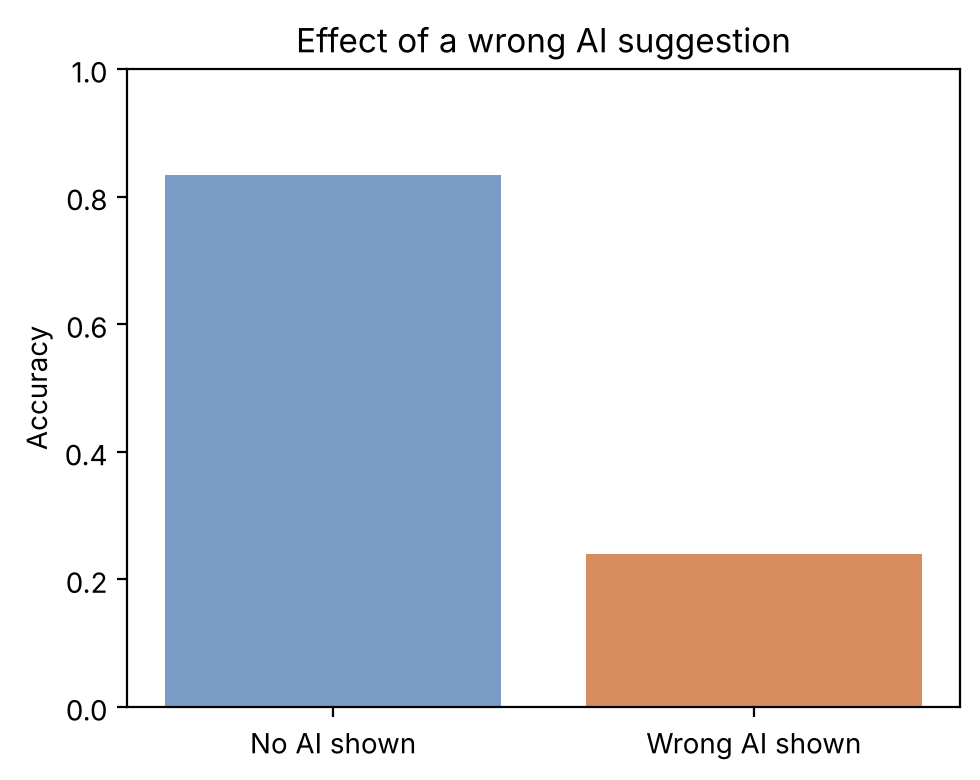

In [7]:
# Compare: on the SAME kind of items where the AI would have been wrong,
# how accurate were people when they did not see the AI at all?
cases = pd.read_csv(ROOT / "data" / "sample_cases.csv")
cases["ai_would_be_wrong"] = cases.ai_flag != cases.ground_truth
off = decisions[decisions.ai_condition == "ai_off"].merge(
    cases[["case_id", "region", "ai_would_be_wrong"]], on=["case_id", "region"])
acc_off_hard = off[off.ai_would_be_wrong].correct.mean()
acc_on_wrong = ai_on[~ai_on.ai_correct].correct.mean()
print(f"Accuracy on 'AI-wrong' items without AI: {acc_off_hard:.0%}")
print(f"Accuracy on 'AI-wrong' items with AI:    {acc_on_wrong:.0%}")

plt.figure(figsize=(5, 4))
plt.bar(["No AI shown", "Wrong AI shown"], [acc_off_hard, acc_on_wrong], color=["#7a9cc6", "#d98c5f"])
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Effect of a wrong AI suggestion")
plt.tight_layout()
plt.savefig(ROOT / "figures" / "automation_bias.png", dpi=150)
plt.show()

## 4. Limitations and next steps

- The data here is simulated; the behaviour model is deliberately simple.
- Real evaluation would need ethics approval, informed consent, realistic cases and
  radiologists as participants, and a proper sample-size calculation.
- Useful extra measures: confidence ratings per decision, eye-tracking or hover time,
  and how explanation design (e.g. showing *why* the AI flagged a region) changes reliance.
- For multi-site studies, mixed-effects models (participant and site as random effects)
  would be more appropriate than simple paired tests.